In [ ]:
%load_ext autoreload
%autoreload 2

In [122]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    root_mean_squared_log_error,
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor, ColumnTransformer

In [120]:
df_raw = pd.read_parquet("../data/processed/df_train.parquet")

In [121]:
df_raw.dtypes

id                           int64
date                datetime64[us]
store_nbr                    int64
family                    category
sales                      float64
onpromotion                  int64
weekday                      int32
month                        int32
week                        UInt32
year                         int32
sales_lag15                float64
sales_lag15_log            float64
sales_lag30                float64
sales_lag30_log            float64
sales_lag365               float64
sales_lag365_log           float64
is_int_sales                  bool
city                           str
state                          str
store_type                category
store_cluster                int64
is_holiday                   int64
dcoilwtico                 float64
transactions               float64
dtype: object

In [ ]:
NUMERIC_FEATURES = ["sales_lag15", "sales_lag30"]
CATEGORICAL_FEATURES = ["store_nbr", "family", "city"]

In [ ]:
def get_linear_regression_pipeline():

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
        ]
    )

    model = Pipeline(
        steps=[
            ("prepprocessor", preprocessor),
            (
                "model",
                TransformedTargetRegressor(
                    regressor=LinearRegression(), func=np.log1p, inverse_func=np.expm1
                ),
            ),
        ]
    )
    return model

In [ ]:
df = df_raw

features = [
    "onpromotion",
    "sales_lag15_log",
    "sales_lag365_log",
    "sales_lag30_log",
]

y = "sales"

horizon = 15
horizon_days = pd.Timedelta(days=horizon)

model = Pipeline(
    steps=[
        (
            "model",
            TransformedTargetRegressor(
                regressor=LinearRegression(), func=np.log1p, inverse_func=np.expm1
            ),
        )
    ]
)

cutoffs = ["2017-07-15", "2017-04-15", "2017-01-15", "2016-09-15"]
cutoffs = pd.to_datetime(cutoffs)


results = []
for cutoff in cutoffs:
    train_df = df[df["date"] < cutoff]
    test_df = df[(df["date"] >= cutoff) & (df["date"] <= (cutoff + horizon_days))]

    X_train, X_test = train_df[features], test_df[features]
    y_train, y_test = train_df[y], test_df[y]

    model.fit(X_train, y_train)
    y_pred = np.clip(model.predict(X_test), a_min=0, a_max=None)

    res = X_test.copy()

    res["store_nbr"] = test_df["store_nbr"]
    res["family"] = test_df["family"]
    res["is_int_sales"] = test_df["is_int_sales"]

    res["date"] = test_df["date"]
    res["y_true"] = y_test
    res["y_pred"] = y_pred
    res["cutoff"] = cutoff

    mask = res["is_int_sales"] == True
    res.loc[mask, "y_pred"] = res.loc[mask, "y_pred"].round()

    mae = mean_absolute_error(y_true=res["y_true"], y_pred=res["y_pred"])
    rmse = np.sqrt(mean_squared_error(y_true=res["y_true"], y_pred=res["y_pred"]))

    print(f"Cutoff: {cutoff}, MAE: {mae:.2f}, RMSE:{rmse:.2f}")
    results.append(res)

df_results = pd.concat(results)

Cutoff: 2017-07-15 00:00:00, MAE: 162.71, RMSE:793.26
Cutoff: 2017-04-15 00:00:00, MAE: 208.64, RMSE:985.01
Cutoff: 2017-01-15 00:00:00, MAE: 214.17, RMSE:1013.11
Cutoff: 2016-09-15 00:00:00, MAE: 158.44, RMSE:787.98


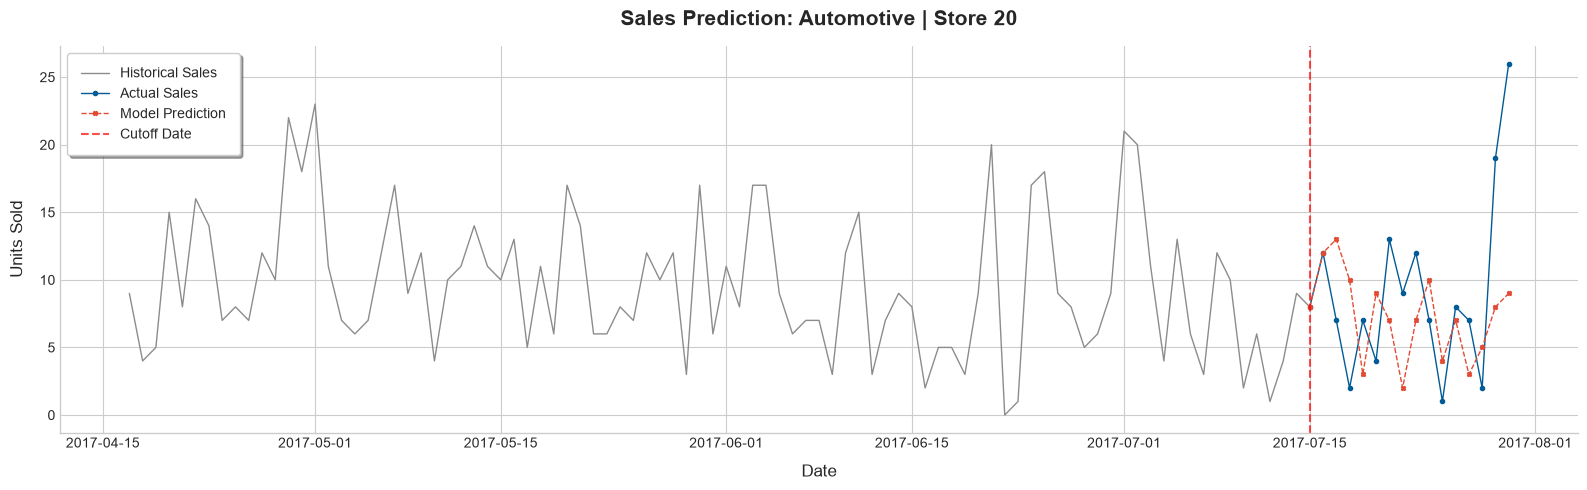

In [111]:
import matplotlib.pyplot as plt
import pandas as pd

family_name = "AUTOMOTIVE"
store_nbr_name = 20
cutoff = pd.to_datetime("2017-07-15")

df_results_filtered = df_results[
    (df_results["family"] == family_name)
    & (df_results["store_nbr"] == store_nbr_name)
    & (df_results["cutoff"] == cutoff)
]
df_filtered = df[
    (df["family"] == family_name)
    & (df["store_nbr"] == store_nbr_name)
    & (df["date"] <= cutoff)
    & (df["date"] > (cutoff - pd.Timedelta(days=90)))
]

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(16, 5))

plt.plot(
    df_filtered["date"],
    df_filtered["sales"],
    color="#8c8c8c",
    linewidth=1,
    label="Historical Sales",
)

plt.plot(
    df_results_filtered["date"],
    df_results_filtered["y_true"],
    color="#005b96",
    linewidth=1,
    marker="o",
    markersize=3,
    label="Actual Sales",
)

plt.plot(
    df_results_filtered["date"],
    df_results_filtered["y_pred"],
    color="#e34a33",
    linewidth=1,
    linestyle="--",
    marker="X",
    markersize=3,
    label="Model Prediction",
)

plt.axvline(
    x=cutoff, color="red", linestyle="--", linewidth=1.5, alpha=0.7, label="Cutoff Date"
)

plt.title(
    f"Sales Prediction: {family_name.title()} | Store {store_nbr_name}",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Date", fontsize=12, labelpad=10)
plt.ylabel("Units Sold", fontsize=12, labelpad=10)

plt.legend(loc="upper left", fontsize=10, frameon=True, shadow=True, borderpad=1)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()